# Laboratorio 22 — PCA desde cero: reducir, quitar ruido y ver

Un conjunto de datos descrito por $p$ features rara vez ocupa las $p$ direcciones: suele
estar cerca de un subespacio de dimensión mucho menor. El análisis de componentes
principales (PCA, *principal component analysis*) encuentra ese subespacio con una sola
operación de álgebra lineal, la descomposición en valores singulares (SVD, *singular value
decomposition*) de la matriz centrada. Este laboratorio responde **qué calcula exactamente
PCA y para qué sirve**:

1. **PCA por SVD, desde cero.** `pca_svd` implementa PCA con `numpy`, a partir del
   pseudocódigo de las notas, y se verifica contra `PCA` de `scikit-learn`. Las componentes
   coinciden salvo el signo, y las coordenadas y las varianzas coinciden exactamente.
2. **Reconstrucción y ruido.** `reconstruir` vuelve de las coordenadas a los datos, se verifica que el error de
   reconstrucción es la suma de los $s_j^2$ descartados, y se elige $M$ para limpiar
   imágenes con ruido **sin ver las imágenes limpias**.
3. **Proyección a 2D.** Se proyecta un agrupamiento de clientes sobre las dos primeras
   componentes y se lee qué dicen los ejes y qué no.
4. **PCA antes de un modelo supervisado.** Se arma `StandardScaler` → `PCA` → modelo,
   se elige $M$ por validación cruzada y se decide si PCA aporta algo frente al modelo sin
   reducir.
5. **Ejercicios estilo parcial**, para resolver por escrito, sin ejecutar código.

Las celdas que contienen `raise NotImplementedError()` deben completarse; las marcadas
`# DECIDE:` piden una decisión con su justificación; el resto es andamiaje y se ejecuta sin
modificar. Cada `### DECIDE` y cada `### Para analizar` se responde en la celda
`**Respuesta:**` que le sigue.

La sección 5 se resuelve por escrito, con el formato de un parcial.

## 0. Preparación

In [1]:
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, clone
from sklearn.cluster import KMeans
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import silhouette_score
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEMILLA = 42

plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)

# Paleta de colores del curso
AZUL = "#19326E"
PALETA = ["#50ACB0", "#CD742A", "#89A943", "#A3477F", "#907FAB", "#4294CC"]
GRIS = "0.55"

In [2]:
# Carga de datos del curso. No hace falta modificar nada.
URL_DATOS = ("https://raw.githubusercontent.com/"
             "ucudal/Machine-Learning---Ingenieria-en-IA-y-CD/main/data/")


def ruta_del_dato(nombre: str) -> Path:
    """Busca el archivo en data/ o en las carpetas data/ de más arriba.

    Si no está y el notebook corre en Colab, lo descarga del repositorio del curso,
    que es privado, con el secreto GITHUB_TOKEN; si eso falla, pide subirlo a mano.
    """
    for carpeta in ["data", "../data", "../../data", "../../../data"]:
        ruta = Path(carpeta) / nombre
        if ruta.exists():
            return ruta

    try:
        from google.colab import files, userdata  # type: ignore
    except ImportError:
        raise FileNotFoundError(f"Falta {nombre}: dejarlo en una carpeta data/ junto al notebook.")

    ruta = Path("data") / nombre
    ruta.parent.mkdir(exist_ok=True)
    try:
        token = userdata.get("GITHUB_TOKEN")
        pedido = urllib.request.Request(URL_DATOS + nombre,
                                        headers={"Authorization": f"token {token}"})
        ruta.write_bytes(urllib.request.urlopen(pedido, timeout=30).read())
    except Exception:
        print(f"No se pudo descargar {nombre}: seleccionar el archivo para subirlo.")
        ruta.write_bytes(files.upload()[nombre])
    return ruta

### Los datos

| Datos | Forma | Sección |
|---|---|---|
| Sintético de baja dimensión, generado en la celda siguiente | $300\times500$ | 1 y 2.1. Cinco direcciones con señal y ruido en las $500$: se conoce la verdad |
| Digits (`load_digits`, incluido en `scikit-learn`) | $1\,797\times64$ | 2.2. Imágenes de $8\times8$ píxeles de dígitos manuscritos, con intensidades de $0$ a $16$ |
| `mall_customers.csv` | $200\times5$ | 3. Clientes de un centro comercial: edad, ingreso anual en miles de dólares y un puntaje de gasto de $1$ a $100$ |
| `ames_reducido.csv` | $1\,460\times9$ | 1 y 4. Ocho features de viviendas de Ames, Iowa, en unidades distintas —superficies en pies cuadrados, año de construcción, calidad de $1$ a $10$— y el precio de venta, `SalePrice` |

> **Antes de ejecutar.** Los dos CSV están en la carpeta `data/` del repositorio del curso.
> Abriendo el notebook desde el repositorio clonado, la celda de carga los encuentra. En
> Colab los descarga del repositorio, que es privado: hace falta cargar un token de GitHub
> con acceso de lectura como secreto `GITHUB_TOKEN` (icono de la llave, en la barra
> lateral). Sin token, la celda ofrece subir cada archivo a mano.

El conjunto sintético se genera en la celda siguiente: cinco variables latentes de desvíos $3$; $2{,}5$; $2$; $1{,}5$ y $1$, mezcladas en
$500$ features, más ruido $\mathbf E$ de varianza $1$ en cada feature.

In [3]:
rng = np.random.default_rng(SEMILLA)
latentes = rng.normal(size=(300, 5)) * [3, 2.5, 2, 1.5, 1]
mezcla = rng.normal(size=(5, 500))
E = rng.normal(size=(300, 500))
X_sint = latentes @ mezcla + E

ames = pd.read_csv(ruta_del_dato("ames_reducido.csv"))
X_ames = ames.drop(columns="SalePrice").to_numpy(dtype=float)
y_ames = ames["SalePrice"].to_numpy(dtype=float)
X_ames_std = StandardScaler().fit_transform(X_ames)

mall = pd.read_csv(ruta_del_dato("mall_customers.csv"))

assert X_sint.shape == (300, 500) and X_ames.shape == (1460, 8) and mall.shape == (200, 5)
print("Datos cargados.")

Datos cargados.


## 1. PCA por SVD, desde cero

Con la matriz centrada $\tilde{\mathbf X}$ y su SVD delgada
$\tilde{\mathbf X}=\mathbf U\mathbf S\mathbf V^\top$, con $r=\min(n,p)$ valores singulares
$s_1\ge\dots\ge s_r$:

- las **componentes principales** son las columnas de $\mathbf V$; las $M$ primeras forman
  $\mathbf V_M$, de $p\times M$;
- las **coordenadas** de las observaciones son $\mathbf Z_M=\tilde{\mathbf X}\mathbf V_M=\mathbf U_M\mathbf S_M$, de $n\times M$;
- la **varianza** a lo largo de la componente $j$ es $s_j^2/(n-1)$, y su **proporción de
  varianza explicada**, $s_j^2/\sum_l s_l^2$.

El pseudocódigo de las notas, escrito con los nombres que usa el código, es el siguiente. La
estandarización, cuando corresponde, se hace **antes** de llamar a la función, con
`StandardScaler`:

```text
Entrada: X (n×p), M
Salida:  media (p), V_M (p×M), Z_M (n×M), varianza (r), proporcion (r)

1.  media ← media de cada columna de X
2.  X_tilde ← X − media
3.  U, s, Vt ← SVD delgada de X_tilde        (s_1 ≥ … ≥ s_r, r = min(n, p))
4.  V_M ← primeras M filas de Vt, traspuestas  (primeras M columnas de V)
5.  Z_M ← X_tilde · V_M                        (igual a U_M · diag(s_1, …, s_M))
6.  varianza ← s² / (n − 1);  proporcion ← s² / Σ s²
7.  devolver media, V_M, Z_M, varianza, proporcion
```

Dos detalles de `numpy` y `scikit-learn` que hay que tener presentes:

- `np.linalg.svd` devuelve $\mathbf V^\top$ (`Vt`), no $\mathbf V$: las componentes son las
  **filas** de `Vt`. `PCA.components_` también las guarda por filas, de modo que
  `components_` es $\mathbf V_M^\top$.
- El signo de cada componente es arbitrario: $\mathbf v_j$ y $-\mathbf v_j$ son la misma
  dirección. La verificación alinea los signos antes de comparar.

### 1.1 La función `pca_svd`

La función siguiente implementa el pseudocódigo con
`np.linalg.svd(X_tilde, full_matrices=False)`, que da la SVD delgada. Conviene leerla línea
por línea contra el pseudocódigo.

In [4]:
def pca_svd(X: np.ndarray, M: int) -> tuple[np.ndarray, np.ndarray, np.ndarray,
                                            np.ndarray, np.ndarray]:
    """PCA de X con M componentes, calculado por la SVD de la matriz centrada.

    Parámetros
    ----------
    X : array (n, p). Si hay que estandarizar, X llega ya estandarizada.
    M : int, cantidad de componentes retenidas, 1 <= M <= min(n, p)

    Devuelve
    --------
    media      : array (p,)    media de cada columna de X
    V_M        : array (p, M)  las M primeras componentes, UNA POR COLUMNA
    Z_M        : array (n, M)  coordenadas de las observaciones, X_tilde @ V_M
    varianza   : array (r,)    s_j^2 / (n - 1) para las r = min(n, p) componentes
    proporcion : array (r,)    s_j^2 / sum(s_l^2), proporción de varianza explicada
    """
    n = X.shape[0]
    media = X.mean(axis=0)
    X_tilde = X - media
    U, s, Vt = np.linalg.svd(X_tilde, full_matrices=False)
    V_M = Vt[:M].T
    Z_M = X_tilde @ V_M
    varianza = s ** 2 / (n - 1)
    proporcion = s ** 2 / np.sum(s ** 2)
    return media, V_M, Z_M, varianza, proporcion

La verificación corre sobre dos matrices: la sintética, con $n<p$, y Ames estandarizado,
con $n>p$. Con $n<p$, una $\mathbf V$ armada al revés —columnas de `Vt` en lugar de
filas— tiene otra forma, y el primer `assert` lo detecta.

In [5]:
# VERIFICACIÓN — contra PCA de scikit-learn, con los signos alineados
for X_prueba, M in [(X_sint, 5), (X_ames_std, 3)]:
    n, p = X_prueba.shape
    media, V_M, Z_M, varianza, proporcion = pca_svd(X_prueba, M)
    assert V_M.shape == (p, M), "V_M tiene que ser (p, M), una componente por columna: svd devuelve Vt"
    assert Z_M.shape == (n, M), "Z_M tiene que ser (n, M)"
    assert varianza.shape == (min(n, p),), "varianza lleva las r = min(n, p) componentes"

    pca = PCA(n_components=M, svd_solver="full").fit(X_prueba)
    signos = np.sign(np.sum(V_M * pca.components_.T, axis=0))   # uno por componente
    assert np.allclose(media, pca.mean_)
    assert np.allclose(V_M * signos, pca.components_.T), "componentes distintas de las de PCA"
    assert np.allclose(Z_M * signos, pca.transform(X_prueba)), "coordenadas distintas"
    assert np.allclose(varianza[:M], pca.explained_variance_), "varianza: revisar el n - 1"
    assert np.allclose(proporcion[:M], pca.explained_variance_ratio_)
    print(f"Matriz de {n} x {p}: pca_svd coincide con PCA de scikit-learn.")

Matriz de 300 x 500: pca_svd coincide con PCA de scikit-learn.
Matriz de 1460 x 8: pca_svd coincide con PCA de scikit-learn.


### 1.2 Cuántas direcciones tiene el conjunto sintético

Los valores singulares se recuperan de la varianza: $s_j=\sqrt{(n-1)\,\text{varianza}_j}$.
El gráfico muestra el espectro en escala logarítmica y la varianza explicada acumulada.

Valores singulares 1 a 8: [1157.54  988.29  755.76  579.99  375.31   39.02   38.77   38.35]
Proporción 1 a 6:         [0.3816 0.2781 0.1627 0.0958 0.0401 0.0004]
M para el 80%: 3
M para el 90%: 4
M para el 95%: 5
M para el 99%: 135
Valores singulares no nulos: 299 de 300


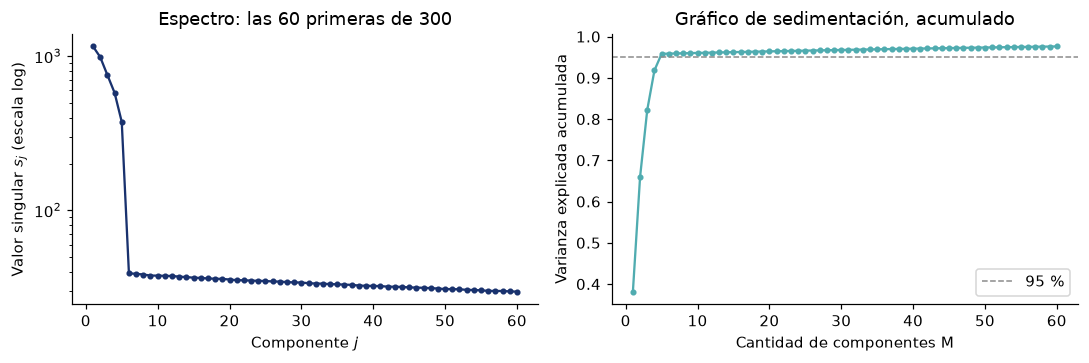

In [6]:
n_sint = X_sint.shape[0]
_, _, _, varianza_sint, proporcion_sint = pca_svd(X_sint, 1)
s_sint = np.sqrt((n_sint - 1) * varianza_sint)
acumulada = np.cumsum(proporcion_sint)
indices = np.arange(1, len(s_sint) + 1)

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.4))
ejes[0].semilogy(indices[:60], s_sint[:60], marker=".", color=AZUL)
ejes[0].set(xlabel="Componente $j$", ylabel="Valor singular $s_j$ (escala log)",
            title="Espectro: las 60 primeras de 300")
ejes[1].plot(indices[:60], acumulada[:60], marker=".", color=PALETA[0])
ejes[1].axhline(0.95, color=GRIS, ls="--", lw=1, label="95 %")
ejes[1].set(xlabel="Cantidad de componentes M", ylabel="Varianza explicada acumulada",
            title="Gráfico de sedimentación, acumulado")
ejes[1].legend()
plt.tight_layout()
plt.show()

print("Valores singulares 1 a 8:", s_sint[:8].round(2))
print("Proporción 1 a 6:        ", proporcion_sint[:6].round(4))
for umbral in (0.80, 0.90, 0.95, 0.99):
    print(f"M para el {umbral:.0%}: {int(np.argmax(acumulada >= umbral)) + 1}")
print("Valores singulares no nulos:", int(np.sum(s_sint > 1e-8 * s_sint[0])), "de", len(s_sint))

### Para analizar

1. ¿Cuántas de las $500$ direcciones hacen falta para el $95\ \%$ de la varianza, y por qué
   el $99\ \%$ exige tantas más? Relacionarlo con cómo se construyeron los datos.
2. La matriz tiene $300$ filas, pero no hay $300$ valores singulares no nulos. ¿De dónde
   sale la diferencia?

**Respuesta:**

1. Hacen falta **5 componentes para el 95 %** y **135 para el 99 %**. Las cinco variables latentes mezcladas concentran el 95.83% de la variación; el resto se reparte en muchas direcciones de ruido de varianza 1. El salto de 95 a 99 % exige conservar mucho de ese ruido, no descubrir 130 fuentes nuevas de señal. El rango algebraico de la matriz observada no es la dimensión de la señal.
2. Hay **299 valores singulares no nulos**, no 300. Al centrar, la suma de las filas es el vector cero: se introduce una dependencia lineal. El rango queda acotado por min(n−1,p)=299. La SVD delgada devuelve 300 valores, pero uno es numéricamente cero.

## 2. Reconstrucción y ruido

### 2.1 La función `reconstruir`

La reconstrucción con $M$ componentes es $\hat{\mathbf X}_M=\mathbf Z_M\mathbf V_M^\top$, en
las unidades de la matriz centrada. La función devuelve `X_hat` $=\hat{\mathbf X}_M+$
`media`, en las unidades de los datos. Las notas muestran que el error de reconstrucción
es la suma de los cuadrados de los valores singulares descartados,

$$
\lVert\tilde{\mathbf X}-\hat{\mathbf X}_M\rVert_F^2=\sum_{j>M}s_j^2=(n-1)\sum_{j>M}\text{varianza}_j ,
$$

Medido entre $\mathbf X$ y `X_hat` el error es el mismo, porque la media se cancela en la
diferencia. La función siguiente implementa la reconstrucción.

In [7]:
def reconstruir(Z_M: np.ndarray, V_M: np.ndarray, media: np.ndarray) -> np.ndarray:
    """Reconstrucción de los datos a partir de sus coordenadas en M componentes.

    Parámetros
    ----------
    Z_M   : array (n, M)  coordenadas
    V_M   : array (p, M)  componentes, una por columna
    media : array (p,)    la media que se restó al centrar

    Devuelve
    --------
    X_hat : array (n, p), la reconstrucción más la media: unidades de los datos
    """
    return Z_M @ V_M.T + media

In [8]:
# VERIFICACIÓN — contra inverse_transform y contra la identidad del error
media, V_M, Z_M, _, _ = pca_svd(X_sint, 5)
pca = PCA(n_components=5, svd_solver="full").fit(X_sint)
assert np.allclose(reconstruir(Z_M, V_M, media), pca.inverse_transform(pca.transform(X_sint)))

total = np.sum((X_sint - X_sint.mean(axis=0)) ** 2)
for M in (2, 5, 40):
    media, V_M, Z_M, varianza, _ = pca_svd(X_sint, M)
    error = np.sum((X_sint - reconstruir(Z_M, V_M, media)) ** 2)
    assert np.isclose(error, (n_sint - 1) * np.sum(varianza[M:])), \
        "el error no coincide con la suma de los s_j^2 descartados"
    print(f"M = {M:>2}: error {error:12.1f}, fracción de la variación total {error / total:.4f}")
print("reconstruir coincide con PCA, y el error es la suma de los s_j² descartados.")

M =  2: error    1195005.4, fracción de la variación total 0.3403
M =  5: error     146586.5, fracción de la variación total 0.0417
M = 40: error     102927.8, fracción de la variación total 0.0293
reconstruir coincide con PCA, y el error es la suma de los s_j² descartados.


### 2.2 Quitar ruido sin ver la imagen limpia

A cada píxel de Digits se le suma ruido independiente $\mathcal N(0,4^2)$, se ajusta PCA
**sobre las imágenes con ruido** y se reconstruye con $M$ componentes. El ruido se reparte por
igual en todas las direcciones, de modo que pesa relativamente más en las de poca varianza,
y proyectar las descarta.

En un problema real **las imágenes limpias no están disponibles**. $M$ se elige con lo que sí se tiene: el espectro de los datos con ruido y las
reconstrucciones. La celda siguiente muestra
las dos cosas. La línea punteada del espectro es su **piso**: la mediana de la segunda
mitad, donde ya casi solo queda ruido.

Varianza de las componentes 1 a 20: [194.9 176.2 162.9 116.3  86.8  76.1  68.4  59.4  57.5  52.9  46.2  44.4
  40.2  38.6  34.5  32.7  32.6  31.   29.   28.3]


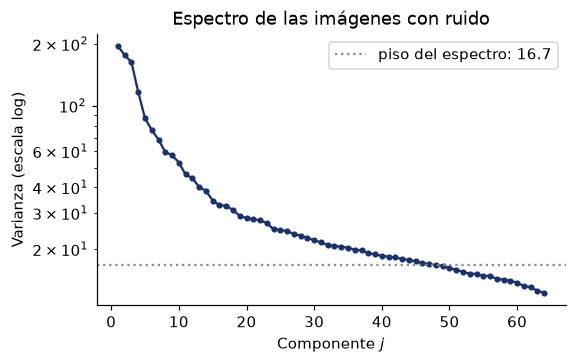

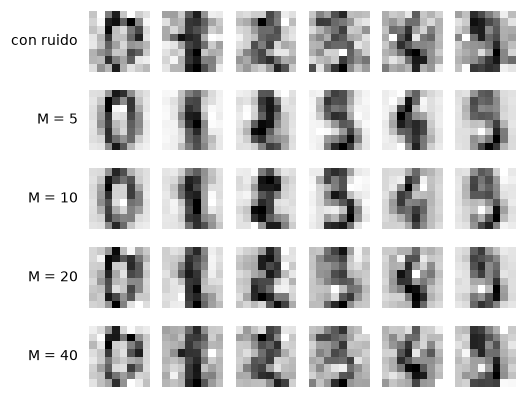

In [9]:
X_dig = load_digits().data                       # (1797, 64), intensidades de 0 a 16
rng = np.random.default_rng(SEMILLA)
X_ruido = X_dig + rng.normal(scale=4, size=X_dig.shape)

media_r, V_r, Z_r, varianza_r, _ = pca_svd(X_ruido, 64)
piso = np.median(varianza_r[32:])


def limpiar(m: int) -> np.ndarray:
    """Reconstruye las imágenes con ruido con sus m primeras componentes."""
    return reconstruir(Z_r[:, :m], V_r[:, :m], media_r)


def mostrar_digitos(filas: list) -> None:
    """Dibuja los seis primeros dígitos de cada matriz: una fila por (rótulo, matriz)."""
    fig, ejes = plt.subplots(len(filas), 6, figsize=(5, 0.9 * len(filas)))
    for f, (rotulo, A) in enumerate(filas):
        for c in range(6):
            ejes[f, c].imshow(A[c].reshape(8, 8), cmap="gray_r")
            ejes[f, c].axis("off")
        ejes[f, 0].text(-2, 3.5, rotulo, ha="right", va="center", fontsize=9)
    plt.show()


plt.figure(figsize=(5.5, 3.2))
plt.semilogy(range(1, 65), varianza_r, marker=".", color=AZUL)
plt.axhline(piso, color=GRIS, ls=":", label=f"piso del espectro: {piso:.1f}")
plt.xlabel("Componente $j$")
plt.ylabel("Varianza (escala log)")
plt.title("Espectro de las imágenes con ruido")
plt.legend()
plt.show()

mostrar_digitos([("con ruido", X_ruido)] + [(f"M = {m}", limpiar(m)) for m in (5, 10, 20, 40)])
print("Varianza de las componentes 1 a 20:", varianza_r[:20].round(1))

### DECIDE

Fijar `M_RUIDO`, la cantidad de componentes con que se limpian las imágenes, usando solo
el espectro y las reconstrucciones de la celda anterior, y justificar el criterio. Pista
de las notas: el error de la reconstrucción es la señal descartada más el ruido retenido,
y cada componente retenida agrega la misma cantidad de ruido.

In [10]:
# DECIDE: se usa únicamente el espectro de las imágenes ruidosas.
# El piso aproxima la varianza del ruido por dirección. Retener una dirección
# agrega ruido; se exige varianza observada mayor que dos veces ese piso.
M_RUIDO = int(np.clip(np.sum(varianza_r > 2 * piso), 1, 64))
print(f'Piso: {piso:.3f}; umbral: {2*piso:.3f}; M_RUIDO: {M_RUIDO}')

Piso: 16.667; umbral: 33.334; M_RUIDO: 15


**Respuesta:** Se fija **M_RUIDO=15**, antes de ejecutar la celda que utiliza las imágenes limpias. El piso estimado únicamente del espectro ruidoso es 16.667; se retienen las componentes con varianza observada mayor que 33.334, dos veces ese piso. Es una regla heurística de compromiso entre señal descartada y ruido retenido: exige una contribución de señal apreciable antes de aceptar el ruido de otra dirección. Las reconstrucciones cercanas a 10–20 componentes conservan trazos con menos fondo que 40; con 5 se pierde estructura. La regla supone ruido aproximadamente isotrópico; no demuestra que el piso sea ruido puro ni garantiza el M óptimo.

La celda siguiente hace lo que en un problema real no se puede: mide el RMSE (*root mean
squared error*, raíz del error cuadrático medio) por píxel **contra las imágenes limpias**,
para todos los $M$, y lo compara con la elección anterior.

RMSE sin proyectar:          4.014
RMSE con M = 15 (elegido):   2.670
RMSE mínimo, con M = 14:     2.669


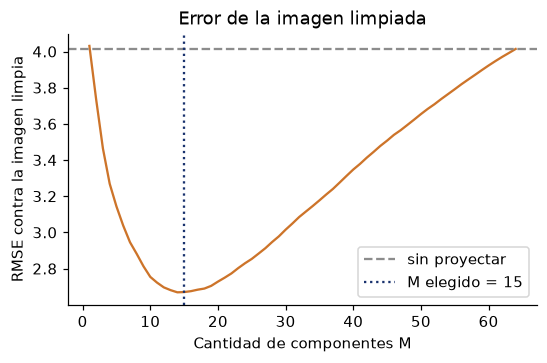

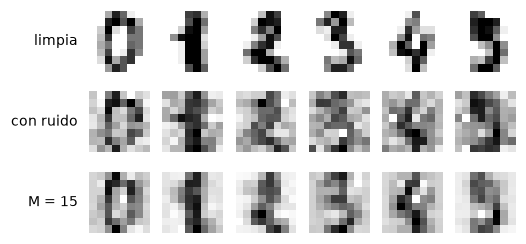

In [11]:
assert M_RUIDO is not None, "Completar M_RUIDO en la celda DECIDE."
assert 1 <= M_RUIDO <= 64, "M_RUIDO tiene que estar entre 1 y 64."

rmse_sin_proyectar = np.sqrt(np.mean((X_ruido - X_dig) ** 2))
errores = [np.sqrt(np.mean((limpiar(m) - X_dig) ** 2)) for m in range(1, 65)]
M_optimo = int(np.argmin(errores)) + 1

plt.figure(figsize=(5.5, 3.2))
plt.plot(range(1, 65), errores, color=PALETA[1])
plt.axhline(rmse_sin_proyectar, color=GRIS, ls="--", label="sin proyectar")
plt.axvline(M_RUIDO, color=AZUL, ls=":", label=f"M elegido = {M_RUIDO}")
plt.xlabel("Cantidad de componentes M")
plt.ylabel("RMSE contra la imagen limpia")
plt.title("Error de la imagen limpiada")
plt.legend()
plt.show()

mostrar_digitos([("limpia", X_dig), ("con ruido", X_ruido), (f"M = {M_RUIDO}", limpiar(M_RUIDO))])
print(f"RMSE sin proyectar:          {rmse_sin_proyectar:.3f}")
print(f"RMSE con M = {M_RUIDO} (elegido):   {errores[M_RUIDO - 1]:.3f}")
print(f"RMSE mínimo, con M = {M_optimo}:     {min(errores):.3f}")

### Para analizar

1. Comparar el $M$ elegido con el que minimiza el RMSE contra las imágenes limpias. ¿Cuánto error adicional
   implica no haber podido mirarlas?
2. ¿Por qué la curva vuelve a subir y, con $M=64$, iguala al RMSE sin proyectar?

**Respuesta:**

1. La elección sin imágenes limpias fue **M=15**; el mínimo evaluado después ocurre en **M=14**. El RMSE por píxel pasa de 4.014031 sin proyección a 2.670192; el mínimo es 2.668824. No poder mirar las limpias cuesta **0.001368** de RMSE adicional, un 0.051 % sobre el óptimo de este experimento. Esa comparación es diagnóstico posterior y no se usa para cambiar M_RUIDO. Se mide sobre las mismas imágenes usadas para PCA; no es un estudio de generalización a imágenes nuevas.
2. Al principio, más componentes recuperan estructura; después se añaden direcciones con poca señal y bastante ruido. Por eso el error frente a la referencia limpia vuelve a subir. Con M=64 se reconstruye exactamente la imagen ruidosa, de modo que se recupera también todo el ruido y el RMSE coincide con el de no proyectar. El error de reconstrucción respecto de la imagen ruidosa, en cambio, decrece hasta cero: son dos errores distintos.

## 3. Proyección a 2D: qué se ve y qué no

Un centro comercial agrupó a $200$ clientes por edad, ingreso y puntaje de gasto,
estandarizados, con k-medias de $K=6$ grupos sobre los **tres** features. Con tres
features el agrupamiento no se puede dibujar directamente; su proyección sobre las dos
primeras componentes, sí. La celda siguiente proyecta los grupos, muestra las **cargas**
—el peso de cada feature en cada componente— y compara la silueta media del agrupamiento
en los tres features con la que se obtiene midiendo distancias en el plano.

Cargas:
           PC1    PC2
edad     0.706  0.030
ingreso -0.048  0.999
gasto   -0.706 -0.038

Proporción de varianza explicada: [0.4427 0.3331 0.2243] | plano: 0.7757
Silueta media en los 3 features: 0.4274
Silueta media medida en el plano: 0.3482

Perfil de cada grupo (medias en unidades originales y centro en el plano):


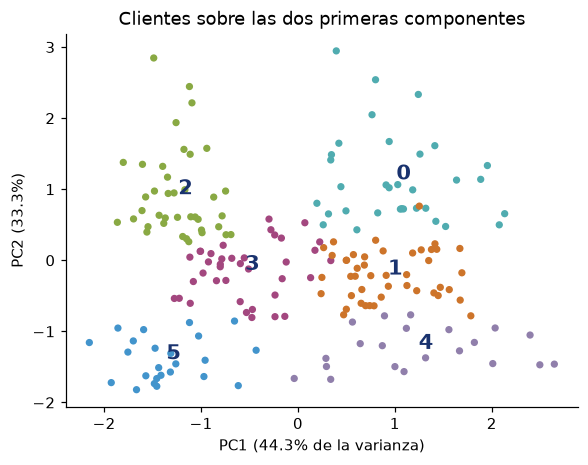

,edad,ingreso,gasto,n,PC1,PC2
0,41.94,88.94,16.97,33,1.02,1.14
1,56.33,54.27,49.07,45,0.93,-0.20
2,32.69,86.54,82.13,39,-1.24,0.93
3,26.68,57.58,47.79,38,-0.55,-0.14
4,45.52,26.29,19.38,21,1.25,-1.25
5,25.25,25.83,76.92,24,-1.36,-1.39


In [12]:
FEATURES_MALL = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
NOMBRES_MALL = ["edad", "ingreso", "gasto"]
X_mall = StandardScaler().fit_transform(mall[FEATURES_MALL])
grupos = KMeans(n_clusters=6, n_init=20, random_state=0).fit_predict(X_mall)

_, V_mall, Z_mall, _, proporcion_mall = pca_svd(X_mall, 2)

plt.figure(figsize=(6, 4.4))
plt.scatter(Z_mall[:, 0], Z_mall[:, 1], c=[PALETA[g] for g in grupos], s=14)
for g in range(6):
    centro = Z_mall[grupos == g].mean(axis=0)
    plt.text(centro[0], centro[1], str(g), fontsize=14, fontweight="bold", color=AZUL)
plt.xlabel(f"PC1 ({proporcion_mall[0]:.1%} de la varianza)")
plt.ylabel(f"PC2 ({proporcion_mall[1]:.1%})")
plt.title("Clientes sobre las dos primeras componentes")
plt.show()

print("Cargas:")
print(pd.DataFrame(V_mall, index=NOMBRES_MALL, columns=["PC1", "PC2"]).round(3))
print("\nProporción de varianza explicada:", proporcion_mall.round(4),
      f"| plano: {proporcion_mall[:2].sum():.4f}")
print(f"Silueta media en los 3 features: {silhouette_score(X_mall, grupos):.4f}")
print(f"Silueta media medida en el plano: {silhouette_score(Z_mall, grupos):.4f}")

perfil = mall[FEATURES_MALL].set_axis(NOMBRES_MALL, axis=1).groupby(grupos).mean()
perfil["n"] = np.bincount(grupos)
perfil[["PC1", "PC2"]] = pd.DataFrame(Z_mall).groupby(grupos).mean().to_numpy()
print("\nPerfil de cada grupo (medias en unidades originales y centro en el plano):")
perfil.round(2)

### Para analizar

1. A partir de las cargas, ¿qué mide cada eje? Ubicar con eso, en el plano, a los clientes
   de ingreso alto y gasto alto, y a los dos grupos de ingreso y gasto medios.
2. El plano conserva algo menos del $78\ \%$ de la varianza, y la silueta medida en él no es
   la del agrupamiento. ¿Qué **no** puede afirmarse a partir del gráfico sobre la calidad de
   los seis grupos?

**Respuesta:**

1. Con la orientación de signos de esta ejecución, **PC1 = +0.706·edad_z -0.048·ingreso_z -0.706·gasto_z; PC2 = +0.030·edad_z +0.999·ingreso_z -0.038·gasto_z**. Las cargas de mayor valor absoluto indican qué variables dominan cada eje; una carga negativa invierte el sentido de lectura y el signo global de una componente puede cambiar sin alterar el resultado. El perfil de ingreso y gasto altos es el **grupo 2**, centrado en (-1.24, 0.93). Los dos perfiles más cercanos a ingreso/gasto medios son: **grupo 3: edad 26.7, ingreso 57.6, gasto 47.8, centro (-0.55, -0.14); grupo 1: edad 56.3, ingreso 54.3, gasto 49.1, centro (0.93, -0.20)**. Se distinguen además por su edad y su posición en el eje que contrapone edad y gasto. Los números de grupo son identificadores arbitrarios, no categorías ordenadas.
2. Las dos componentes conservan 77.57% de la variación y omiten 22.43%. La silueta en tres dimensiones es 0.4274, frente a 0.3482 en el plano. Son geometrías distintas: la proyección no preserva todas las distancias ni las relaciones de vecindad. No puede afirmarse que seis sea el K óptimo, que haya seis poblaciones naturales, ni que la separación o superposición visible represente exactamente la calidad del agrupamiento original. Tres features sí se pueden dibujar en 3D; la proyección 2D facilita la lectura, pero no valida los grupos.

## 4. PCA antes de un modelo supervisado

¿Reducir los ocho features de Ames a $M$ componentes mejora la predicción del precio?
PCA se ajusta con datos —medias, desvíos, componentes—, de modo que tiene que ajustarse
**dentro de cada fold** de la validación cruzada, solo con los folds de entrenamiento. Si se
ajusta antes, sobre el conjunto entero, la validación mide un modelo que ya vio los datos
con que se lo evalúa: es *data leakage*, información del conjunto de evaluación que
entra en el ajuste. Un `Pipeline` resuelve eso:
encadena pasos que se ajustan en orden, cada uno sobre la salida del anterior, y se trata
como un único modelo.

Se comparan dos modelos con la misma partición, `KFold(5, shuffle=True, random_state=0)`:
una **regresión lineal** y **k vecinos** con $k=10$ (`KNeighborsRegressor`, elegido por
validación cruzada en $\{3,5,10,15,20,30\}$). La métrica es el $R^2$ sobre `SalePrice`.

### 4.1 La función `construir_pipeline`

Corresponde construir el `Pipeline` con tres pasos opcionales en este orden y con estos
nombres: `"escala"` (`StandardScaler`), `"pca"` (`PCA` con $M$ componentes) y `"modelo"`.
Los nombres importan: `GridSearchCV` varía $M$ a través de `"pca__n_components"`. Usar
`clone(modelo)` para que dos pipelines no compartan el mismo objeto.

In [13]:
def construir_pipeline(modelo: BaseEstimator, escalar: bool, usar_pca: bool,
                       M: int = 2) -> Pipeline:
    """Pipeline [StandardScaler] -> [PCA(M)] -> modelo.

    Parámetros
    ----------
    modelo   : estimador de scikit-learn, sin ajustar; va clonado como último paso
    escalar  : si True, el pipeline empieza con un paso de estandarización
               llamado "escala"
    usar_pca : si True, sigue un paso "pca" que retiene M componentes
    M        : cantidad de componentes, si usar_pca

    Devuelve
    --------
    Pipeline cuyos pasos se llaman "escala", "pca" y "modelo", en ese orden,
    con los dos primeros solo si corresponden.
    """
    pasos = []
    if escalar:
        pasos.append(("escala", StandardScaler()))
    if usar_pca:
        pasos.append(("pca", PCA(n_components=M, svd_solver="full")))
    pasos.append(("modelo", clone(modelo)))
    return Pipeline(pasos)

In [14]:
# VERIFICACIÓN — estructura del pipeline en las cuatro combinaciones
for escalar in (True, False):
    for usar_pca in (True, False):
        tubo = construir_pipeline(LinearRegression(), escalar, usar_pca, M=3)
        nombres = list(tubo.named_steps)
        esperado = ["escala"] * escalar + ["pca"] * usar_pca + ["modelo"]
        assert nombres == esperado, f"pasos {nombres}, se esperaba {esperado}"
        if usar_pca:
            assert tubo.named_steps["pca"].n_components == 3, "M tiene que llegar a PCA"

base = LinearRegression()
assert construir_pipeline(base, True, True).named_steps["modelo"] is not base, \
    "el modelo tiene que ir clonado"
print("Estructura del pipeline verificada.")

Estructura del pipeline verificada.


### 4.2 Elegir $M$ por validación cruzada

$M$ es un hiperparámetro del procedimiento completo: se elige por el $R^2$ de validación
cruzada del modelo que sigue a PCA. Corresponde implementar `elegir_M` con `GridSearchCV`
sobre $M\in\{1,\dots,8\}$, la partición `KF` y `scoring="r2"`.

In [15]:
KF = KFold(5, shuffle=True, random_state=0)
MODELOS = {"regresión lineal": LinearRegression(),
           "k vecinos (k = 10)": KNeighborsRegressor(n_neighbors=10)}

In [16]:
def elegir_M(modelo: BaseEstimator, X: np.ndarray, y: np.ndarray) -> GridSearchCV:
    """Búsqueda de M para StandardScaler -> PCA(M) -> modelo, con validación cruzada.

    Usa el pipeline escalado con PCA de construir_pipeline y busca M en 1, ..., 8
    con validación cruzada sobre la partición KF, con el R² como criterio.

    Devuelve
    --------
    El GridSearchCV ya ajustado (con .fit(X, y)).
    """
    tubo = construir_pipeline(modelo, escalar=True, usar_pca=True)
    busqueda = GridSearchCV(tubo, {"pca__n_components": list(range(1, 9))},
                            cv=KF, scoring="r2", refit=True, n_jobs=1)
    return busqueda.fit(X, y)

In [17]:
# VERIFICACIÓN — la búsqueda recorre M = 1..8 con la partición KF
busquedas = {nombre: elegir_M(modelo, X_ames, y_ames) for nombre, modelo in MODELOS.items()}
for nombre, busqueda in busquedas.items():
    M_cv = busqueda.cv_results_["param_pca__n_components"]
    assert list(M_cv) == list(range(1, 9)), "la grilla tiene que ser M = 1, ..., 8"
    assert busqueda.n_splits_ == 5
    M_mejor = busqueda.best_params_["pca__n_components"]
    control = cross_val_score(construir_pipeline(MODELOS[nombre], True, True, M_mejor),
                              X_ames, y_ames, cv=KF, scoring="r2").mean()
    assert np.isclose(busqueda.best_score_, control), "la búsqueda no usó la partición KF"
    print(f"{nombre}: M elegido = {M_mejor}, R² medio = {busqueda.best_score_:.4f}")

regresión lineal: M elegido = 5, R² medio = 0.7629
k vecinos (k = 10): M elegido = 5, R² medio = 0.8210


### 4.3 Con PCA, sin PCA y PCA sin escalar

La celda siguiente evalúa, con las mismas cinco particiones, cuatro configuraciones de cada
modelo y muestra el $R^2$ **fold por fold**: sin escalar ni PCA; escalado, sin PCA;
escalado más PCA con el $M$ elegido; y PCA con el mismo $M$, sin escalar. Debajo de cada
tabla se imprime la diferencia, por fold, entre PCA con el $M$ elegido y el modelo escalado
sin PCA. El gráfico muestra la curva de validación de $M$, con una banda de un desvío entre folds.

El $M$ se eligió con las mismas particiones con que ahora se compara: la ganancia de PCA puede
estar sobrestimada. Una estimación sin ese sesgo requiere validación cruzada anidada.


REGRESIÓN LINEAL
        sin escalar ni PCA  escalado, sin PCA  escalado + PCA, M = 5  PCA sin escalar, M = 5
fold 1              0.6405             0.6405                 0.6479                  0.4937
fold 2              0.8089             0.8089                 0.8083                  0.7650
fold 3              0.7748             0.7748                 0.7734                  0.6757
fold 4              0.7805             0.7805                 0.7891                  0.7159
fold 5              0.7911             0.7911                 0.7961                  0.7341
media               0.7592             0.7592                 0.7629                  0.6769
desvío              0.0676             0.0676                 0.0655                  0.1074
PCA M = 5 menos escalado sin PCA, por fold: [0.0073, -0.0007, -0.0015, 0.0086, 0.005]
  media +0.0038, desvío 0.0046, a favor de PCA en 3 de 5 folds

K VECINOS (K = 10)
        sin escalar ni PCA  escalado, sin PCA  escalado + PCA, M = 5 

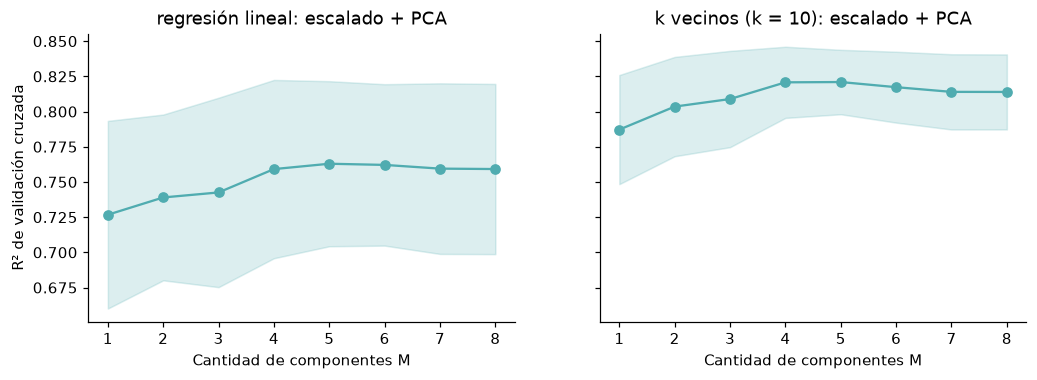

In [18]:
def r2_por_fold(modelo: BaseEstimator, escalar: bool, usar_pca: bool, M: int = 2) -> np.ndarray:
    tubo = construir_pipeline(modelo, escalar, usar_pca, M)
    return cross_val_score(tubo, X_ames, y_ames, cv=KF, scoring="r2")


tablas_modelos, diferencias_modelos = {}, {}
for nombre, modelo in MODELOS.items():
    M_mejor = busquedas[nombre].best_params_["pca__n_components"]
    tabla = pd.DataFrame({
        "sin escalar ni PCA": r2_por_fold(modelo, False, False),
        "escalado, sin PCA": r2_por_fold(modelo, True, False),
        f"escalado + PCA, M = {M_mejor}": r2_por_fold(modelo, True, True, M_mejor),
        f"PCA sin escalar, M = {M_mejor}": r2_por_fold(modelo, False, True, M_mejor),
    }, index=[f"fold {i}" for i in range(1, 6)])
    diferencia = tabla.iloc[:, 2] - tabla.iloc[:, 1]
    tabla.loc["media"] = tabla.iloc[:5].mean()
    tabla.loc["desvío"] = tabla.iloc[:5].std()

    tablas_modelos[nombre] = tabla.copy()
    diferencias_modelos[nombre] = diferencia.copy()
    print(f"\n{nombre.upper()}")
    print(tabla.round(4).to_string())
    print(f"PCA M = {M_mejor} menos escalado sin PCA, por fold: {diferencia.round(4).tolist()}")
    print(f"  media {diferencia.mean():+.4f}, desvío {diferencia.std():.4f}, "
          f"a favor de PCA en {(diferencia > 0).sum()} de 5 folds")

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, (nombre, busqueda) in zip(ejes, busquedas.items()):
    media_cv = busqueda.cv_results_["mean_test_score"]
    desvio_cv = busqueda.cv_results_["std_test_score"]
    ax.plot(range(1, 9), media_cv, marker="o", color=PALETA[0])
    ax.fill_between(range(1, 9), media_cv - desvio_cv, media_cv + desvio_cv,
                    color=PALETA[0], alpha=0.2)
    ax.set(xlabel="Cantidad de componentes M", title=f"{nombre}: escalado + PCA")
ejes[0].set_ylabel("R² de validación cruzada")
plt.show()

### DECIDE

1. Para cada modelo, ¿qué configuración se lleva a producción: escalado sin PCA, o escalado
   más PCA con el $M$ elegido? Justificar con las diferencias **por fold**, no solo con las
   medias.
2. ¿Qué decisión de preparación pesa más en este problema, escalar o reducir? Responder con
   las cifras de PCA sin escalar.

**Respuesta:**

1. **regresión lineal: elegiría escalado sin PCA.** M seleccionado=5; R² medio sin PCA=0.7592, con PCA=0.7629. Diferencias PCA−sin PCA por fold: [0.0073, -0.0007, -0.0015, 0.0086, 0.005]; media +0.0038, desvío muestral 0.0046, mejora en 3/5 y empeora en 2/5 (tolerancia 1e−10). Con PCA sin escalar, el R² medio es 0.6769.

**k vecinos (k = 10): elegiría escalado más PCA.** M seleccionado=5; R² medio sin PCA=0.8139, con PCA=0.8210. Diferencias PCA−sin PCA por fold: [0.0096, 0.003, 0.0173, 0.0012, 0.004]; media +0.0070, desvío muestral 0.0066, mejora en 5/5 y empeora en 0/5 (tolerancia 1e−10). Con PCA sin escalar, el R² medio es 0.7151.

No tomaría una ganancia pequeña sobre los mismos folds usados para elegir M como evidencia concluyente de mejora en producción: falta CV anidada o test independiente. Con las ocho componentes completas, PCA solo rota el espacio; una regresión lineal con intercepto conserva las predicciones y k-NN conserva distancias euclidianas tras estandarizar, salvo redondeo.

2. **En k-NN pesa más escalar:** el R² pasa de 0,7195 crudo a 0,8139 escalado (+0,0944), mientras que añadir PCA al escalado aporta +0,0070. PCA sin escalar deja R²=0,7151, frente a 0,8210 con escalado + PCA: reducir no sustituye al escalado. La escala define las distancias y cambia los vecinos; superficies y año no deberían dominar por sus unidades. En regresión lineal sin penalización, cambiar escalas es una reparametrización: con y sin escalado se obtiene R²=0,7592. Allí no hay ganancia por escalar, pero truncar PCA sin escala sí perjudica: R²=0,6769 frente a 0,7629 con escala. El M usado sin escalar fue elegido en el pipeline escalado: es una comparación de preparación con M fijo, no una optimización del pipeline sin escala.

### Conclusión del experimento

Escribir en dos o tres líneas qué aporta PCA a la predicción del precio en Ames, con la
variabilidad entre folds como argumento.

**Respuesta:**

En Ames, PCA con M=5 aporta a la regresión lineal una mejora pequeña e inconstante (ΔR² medio +0,0038; gana en 3/5 folds), por lo que mantendría el modelo sin reducir. En k-NN la mejora es también modesta, pero aparece en los cinco folds (ΔR² +0,0070), y elegiría escalado + PCA como candidato. La comparación reutiliza los folds de selección de M: falta validación anidada o test independiente para confirmar la ganancia.

## 5. Ejercicios estilo parcial

Se resuelven **por escrito**, con el formato de los parciales, sin ejecutar código. Los casos son ficticios.

Los dos son de **análisis crítico de código**: el código ejecuta sin error y produce las
salidas que se muestran; la falencia, si la hay, es conceptual o metodológica, y las
salidas alcanzan para deducirla.

### 5.1 PCA antes de un clasificador de fallas

Una planta química quiere anticipar fallas en sus intercambiadores de calor. Cada hora
registra ocho mediciones de cada equipo: temperaturas y presiones de entrada y de salida,
caudal y potencia de la bomba, entre otras. Registra también si el equipo falló en las 24
horas siguientes (`falla_24h`, $1$ si falló). Como los sensores están muy correlacionados, el
equipo de datos reduce la dimensión con PCA antes de una regresión logística.

```python
import ...

datos = pd.read_csv("intercambiadores_2025.csv")
X = datos.drop(columns="falla_24h")
y = datos["falla_24h"]
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.25, random_state=0)

modelo = make_pipeline(StandardScaler(), PCA(n_components=0.95), LogisticRegression())
modelo.fit(X_ent, y_ent)

pca = modelo.named_steps["pca"]
print("Componentes retenidas:", pca.n_components_)
print("Varianza explicada:", pca.explained_variance_ratio_.round(3))
print("Proporción de fallas en prueba:", round(y_pru.mean(), 3))
print("Accuracy en prueba:", round(modelo.score(X_pru, y_pru), 3))
```

**Salida en consola**

```text
Componentes retenidas: 3
Varianza explicada: [0.778 0.16  0.05 ]
Proporción de fallas en prueba: 0.228
Accuracy en prueba: 0.772
```

El informe a la gerencia dice: «Tres componentes conservan el $98{,}8\ \%$ de la información
de los ocho sensores, de modo que la reducción no pierde nada relevante. Aun así, el modelo
acierta solo en el $77{,}2\ \%$ de los casos: las mediciones disponibles no alcanzan para
anticipar fallas, y se descarta el sistema de alerta».

**Preguntas**

1. **Análisis crítico:** identifique y explique qué falencia conceptual o metodológica
   presenta el flujo de trabajo, a partir del código y de las salidas. *(2 puntos)*
2. **Impacto en el modelo:** explique cómo afecta esa falencia al funcionamiento interno del
   algoritmo y qué consecuencias tiene sobre el modelo final. *(2 puntos)*
3. **Propuesta de corrección:** indique cuál sería la corrección adecuada. *(1 punto)*

**Respuesta:**

1. El informe confunde **varianza explicada de los sensores con información predictiva sobre fallas**. PCA no utiliza `falla_24h`: el 98,8 % describe dispersión de X, no el porcentaje de señal útil para clasificar. Además, 77,2 % de accuracy coincide con predecir siempre «no falla»: 1 − 0,228 = 0,772. La igualdad no prueba que todas las predicciones sean negativas, pero muestra que ese accuracy no acredita superar la referencia trivial. El `Pipeline` sí evita ajustar escalado/PCA sobre prueba; no corresponde acusarlo de esa fuga. El split aleatorio de observaciones horarias puede mezclar horas cercanas de un mismo equipo y horizontes de 24 h superpuestos: falta una validación temporal adecuada.

2. La regresión logística recibe solo las tres coordenadas retenidas. Sus coeficientes efectivos en el espacio estandarizado pertenecen al subespacio de esas componentes; una señal discriminante que viva en una dirección descartada no puede recuperarse ajustando la logística. Una dirección de mucha varianza puede reflejar condiciones normales de operación, mientras que una variación pequeña puede anticipar una falla. El accuracy oculta cómo se reparten falsos positivos y falsos negativos y no justifica concluir que los sensores no sirven. La dependencia temporal también puede hacer optimista la evaluación.

3. Compararía el pipeline escalado sin PCA con varios M y valores de regularización, seleccionados en validación temporal interna; reservaría un período futuro para evaluación final, con separación suficiente para impedir superposición de etiquetas de 24 h entre períodos. Si se busca generalizar a equipos nuevos, separaría también por equipo. Reportaría matriz de confusión, recall/precision de fallas, PR-AUC y costos de errores frente a un baseline; el umbral se ajusta en entrenamiento/validación, sin tocar el test. Solo después evaluaría conservar PCA y la utilidad operativa del sistema.

### 5.2 Tres segmentos de clientes, vistos en dos dimensiones

Una cadena de supermercados describe a $1\,500$ clientes con diez features de su
comportamiento de compra del último año: frecuencia de visitas, ticket medio, proporción
de compras en oferta y otras. El área de marketing quiere segmentarlos para diseñar una
campaña distinta por segmento. El equipo de datos agrupa con k-medias y, para validar el
resultado, proyecta los clientes sobre las dos primeras componentes principales.

```python
import ...

clientes = pd.read_csv("clientes_2025.csv")
X = StandardScaler().fit_transform(clientes)
print(X.shape)

grupos = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X)
print("Clientes por grupo:", np.bincount(grupos))
print("Silueta media:", round(silhouette_score(X, grupos), 3))

pca = PCA(n_components=2)
Z = pca.fit_transform(X)
print("Varianza explicada:", pca.explained_variance_ratio_.round(3))

plt.scatter(Z[:, 0], Z[:, 1], c=grupos, s=8)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()
```

**Salida en consola**

```text
(1500, 10)
Clientes por grupo: [654 405 441]
Silueta media: 0.126
Varianza explicada: [0.403 0.149]
```

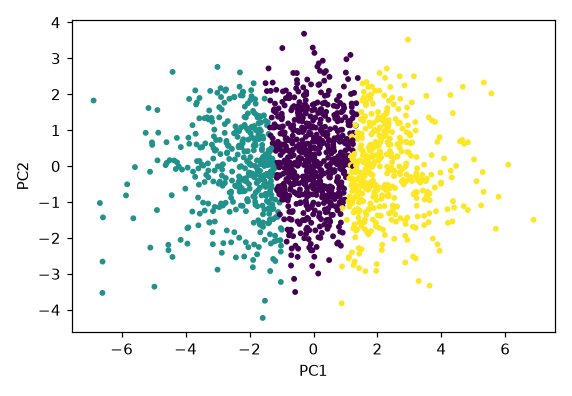

El informe al área de marketing dice: «La proyección muestra tres grupos de clientes
nítidamente separados, sin superposición entre ellos. La segmentación en tres perfiles
queda confirmada, y se diseña una campaña para cada uno».

**Preguntas**

1. **Análisis crítico:** identifique y explique qué falencia conceptual o metodológica
   presenta el flujo de trabajo, a partir del código, las salidas y la figura. *(2 puntos)*
2. **Impacto en el modelo:** explique cómo afecta esa falencia al funcionamiento interno del
   algoritmo y qué consecuencias tiene sobre el resultado final. *(2 puntos)*
3. **Propuesta de corrección:** indique cuál sería la corrección adecuada. *(1 punto)*

**Respuesta:**

1. Se valida una segmentación de diez dimensiones por la apariencia de una proyección de solo dos. PC1 y PC2 conservan 0,403 + 0,149 = **55,2 %** de la varianza y descartan **44,8 %**. PCA maximiza varianza, no separación de grupos, y el color proviene de k-medias: no es evidencia externa de tres segmentos naturales. La silueta en el espacio donde se ajustó k-medias es **0,126**, baja y poco compatible con afirmar una segmentación nítida solo por la figura. No constituye por sí sola una prueba de inutilidad comercial, pero exige más evidencia.

2. K-medias asigna cada observación al centroide más cercano y produce tres grupos porque se fijó K=3, incluso si no hay tres poblaciones bien separadas. PCA se aplica después: no cambia las etiquetas, los centroides ni la función objetivo del modelo ya ajustado; la falencia está en cómo se interpreta y valida el resultado. La proyección modifica distancias y vecinos y puede ocultar diferencias o superposición en las ocho direcciones omitidas. Tener tamaños 654/405/441 tampoco prueba calidad. Diseñar campañas definitivas con esa única evidencia puede separar clientes parecidos o mezclar perfiles relevantes.

3. Evaluaría varios K con silueta en las diez variables estandarizadas, estabilidad ante semillas y remuestreo y perfiles en unidades originales. Revisaría outliers y si las distancias de k-medias representan el problema, comparando otras alternativas cuando corresponda. Usaría PCA como visualización con el porcentaje retenido explícito y, si aporta, más componentes o vistas complementarias. La utilidad comercial se contrasta con diferencias accionables y campañas piloto, no con un scatterplot coloreado.

## Cierre

- PCA es una SVD de la matriz centrada: las componentes son las columnas de $\mathbf V$, las
  coordenadas $\mathbf U_M\mathbf S_M$ y la varianza de cada una $s_j^2/(n-1)$. Cuesta
  $O(np\min(n,p))$, sin iteraciones ni criterio de parada.
- Reconstruir con $M$ componentes deja un error igual a la suma de los $s_j^2$ descartados;
  si el ruido se reparte en todas las direcciones y la señal en pocas, ese recorte lo quita.
- $M$ es una decisión: el espectro la orienta cuando no hay tarea, y la validación cruzada
  la toma cuando hay un modelo detrás. Una proyección a 2D sirve para leer grupos, no para
  validarlos.

## Para seguir explorando

- Repetir la sección 1.2 con una matriz de $300\times500$ de ruido independiente, del mismo
  desvío por columna que `X_sint`. ¿Cuántas componentes pide ahora el $95\ \%$?
- Repetir la sección 3 sin estandarizar los tres features de los clientes y comparar las
  cargas.

## Exploraciones resueltas

Se desarrollan las dos propuestas de «Para seguir explorando». En la segunda se mantienen las etiquetas del k-medias original para aislar el efecto de cambiar solamente la escala de PCA.

M para 95 % — señal + ruido: 5 | ruido independiente: 209
Cargas sin estandarizar:
            PC1     PC2
edad     0.1890 -0.1310
ingreso -0.5886 -0.8084
gasto   -0.7860  0.5739
Varianza explicada cruda: [0.4513 0.441  0.1078]
Desvíos originales: {'Age': 13.969, 'Annual Income (k$)': 26.265, 'Spending Score (1-100)': 25.824}


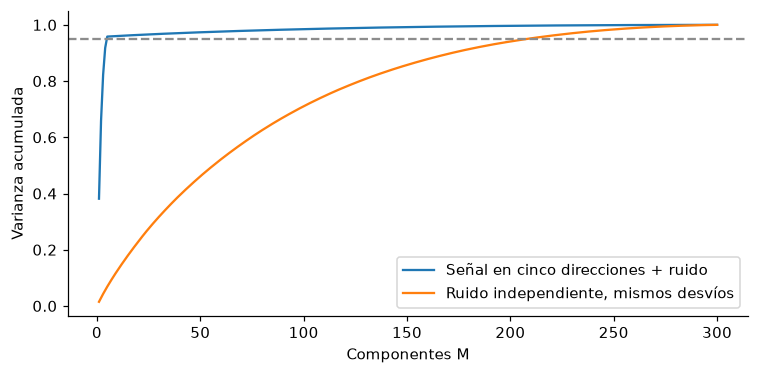

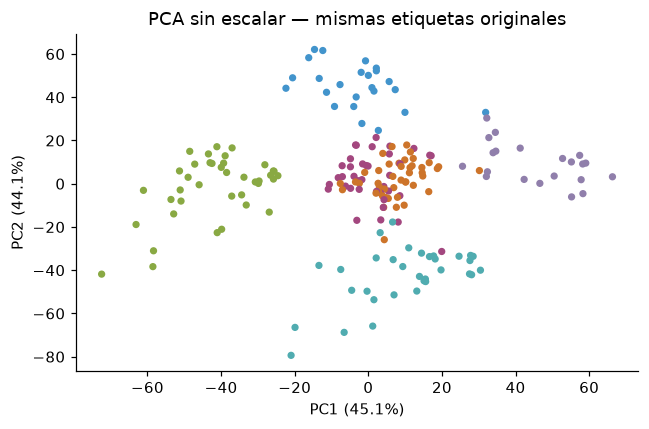

In [19]:
# Exploración 1: ruido independiente con el mismo desvío por columna.
rng_extra = np.random.default_rng(SEMILLA + 1)
X_solo_ruido = rng_extra.normal(size=X_sint.shape)
X_solo_ruido -= X_solo_ruido.mean(axis=0)
X_solo_ruido *= X_sint.std(axis=0, ddof=1) / X_solo_ruido.std(axis=0, ddof=1)
assert np.allclose(X_solo_ruido.std(0,ddof=1), X_sint.std(0,ddof=1))
_, _, _, varianza_solo_ruido, proporcion_solo_ruido = pca_svd(X_solo_ruido, 1)
acumulada_solo_ruido = np.cumsum(proporcion_solo_ruido)
M95_solo_ruido = int(np.searchsorted(acumulada_solo_ruido, 0.95)+1)
print('M para 95 % — señal + ruido:', int(np.searchsorted(acumulada,.95)+1),
      '| ruido independiente:', M95_solo_ruido)
fig,ax=plt.subplots(figsize=(7,3.5))
ax.plot(np.arange(1,301),acumulada,label='Señal en cinco direcciones + ruido')
ax.plot(np.arange(1,301),acumulada_solo_ruido,label='Ruido independiente, mismos desvíos')
ax.axhline(.95,color=GRIS,ls='--'); ax.set(xlabel='Componentes M',ylabel='Varianza acumulada')
ax.legend(); plt.tight_layout(); plt.show()

# Exploración 2: misma segmentación original, proyección sin estandarizar.
X_mall_crudo = mall[FEATURES_MALL].to_numpy(dtype=float)
_, V_mall_crudo, Z_mall_crudo, _, proporcion_mall_crudo = pca_svd(X_mall_crudo, 2)
print('Cargas sin estandarizar:')
print(pd.DataFrame(V_mall_crudo,index=NOMBRES_MALL,columns=['PC1','PC2']).round(4))
print('Varianza explicada cruda:', proporcion_mall_crudo.round(4))
print('Desvíos originales:', mall[FEATURES_MALL].std().round(3).to_dict())
fig,ax=plt.subplots(figsize=(6,4))
ax.scatter(Z_mall_crudo[:,0],Z_mall_crudo[:,1],c=[PALETA[g] for g in grupos],s=14)
ax.set(xlabel=f'PC1 ({proporcion_mall_crudo[0]:.1%})',ylabel=f'PC2 ({proporcion_mall_crudo[1]:.1%})',title='PCA sin escalar — mismas etiquetas originales')
plt.tight_layout(); plt.show()


**Análisis de las exploraciones:**

1. Con ruido independiente se necesitan **209 componentes** para 95 %, frente a 5 cuando hay señal en cinco direcciones. Igualar los desvíos marginales no reproduce las correlaciones: el ruido no tiene las cinco fuentes compartidas que generaban el espectro con un gran codo. Por eso PCA no puede comprimir cualquier conjunto a cinco dimensiones solo porque tenga la misma escala por feature.
2. Sin estandarizar, las dos componentes conservan 89.22% de la varianza medida en unidades originales. Las cargas cambian porque PCA prioriza varianzas absolutas; edad, ingreso y puntaje no comparten unidades ni desvíos. Ese porcentaje no es directamente comparable con el estandarizado como si ambos usaran la misma geometría. Las etiquetas y el ajuste original de k-medias se mantuvieron: el cambio del gráfico proviene de PCA y la escala, no de una nueva segmentación. Si también se elimina el escalado de k-medias, se cambian además las distancias del agrupamiento y puede cambiar la partición.